# Wilkinson Power Divider

In this notebook we create a [Wilkinson power divider](https://www.microwaves101.com/encyclopedias/wilkinson-power-splitters), which splits an input signal into two equals phase output signals. Theoretical results about this circuit are exposed in reference [1]. Here we will reproduce the ideal circuit illustrated below and discussed in reference [2]. In this example, the circuit is designed to operate at 1 GHz.

<img src="wilkinson_power_divider.png">

 - [1] P. Hallbjörner, Microw. Opt. Technol. Lett. 38, 99 (2003).
 - [2] Microwaves 101: "Wilkinson Power Splitters" 

In [1]:
# standard imports
import matplotlib.pyplot as plt
import numpy as np

import skrf as rf
from skrf.circuit import Circuit

rf.stylely()

In [2]:
# frequency band
freq = rf.Frequency(start=0, stop=2, npoints=501, unit='GHz')

# characteristic impedance of the ports
z0_ports = 50

# resistor
R = 100
line_resistor = rf.media.DefinedGammaZ0(frequency=freq, z0=R)
resistor = line_resistor.resistor(R, name='resistor')

# branches
z0_branches = np.sqrt(2)*z0_ports
beta = freq.w/rf.constants.c
line_branches = rf.media.DefinedGammaZ0(frequency=freq, z0=z0_branches, gamma=0+beta*1j)

d = line_branches.theta_2_d(90, deg=True)  # @ 90°(lambda/4)@ 1 GHz is ~ 75 mm
branch1 = line_branches.line(d, unit='m', name='branch1')
branch2 = line_branches.line(d, unit='m', name='branch2')

# ports
port1 = Circuit.Port(freq, name='port1', z0=50)
port2 = Circuit.Port(freq, name='port2', z0=50)
port3 = Circuit.Port(freq, name='port3', z0=50)

# Connection setup
#┬Note that the order of appearance of the port in the setup is important
connections = [
           [(port1, 0), (branch1, 0), (branch2, 0)],
           [(port2, 0), (branch1, 1), (resistor, 0)],
           [(port3, 0), (branch2, 1), (resistor, 1)]
        ]

# Building the circuit
C = Circuit(connections)

The circuit setup can be checked by visualising the circuit graph (this requires the python package `networkx` to be available). 

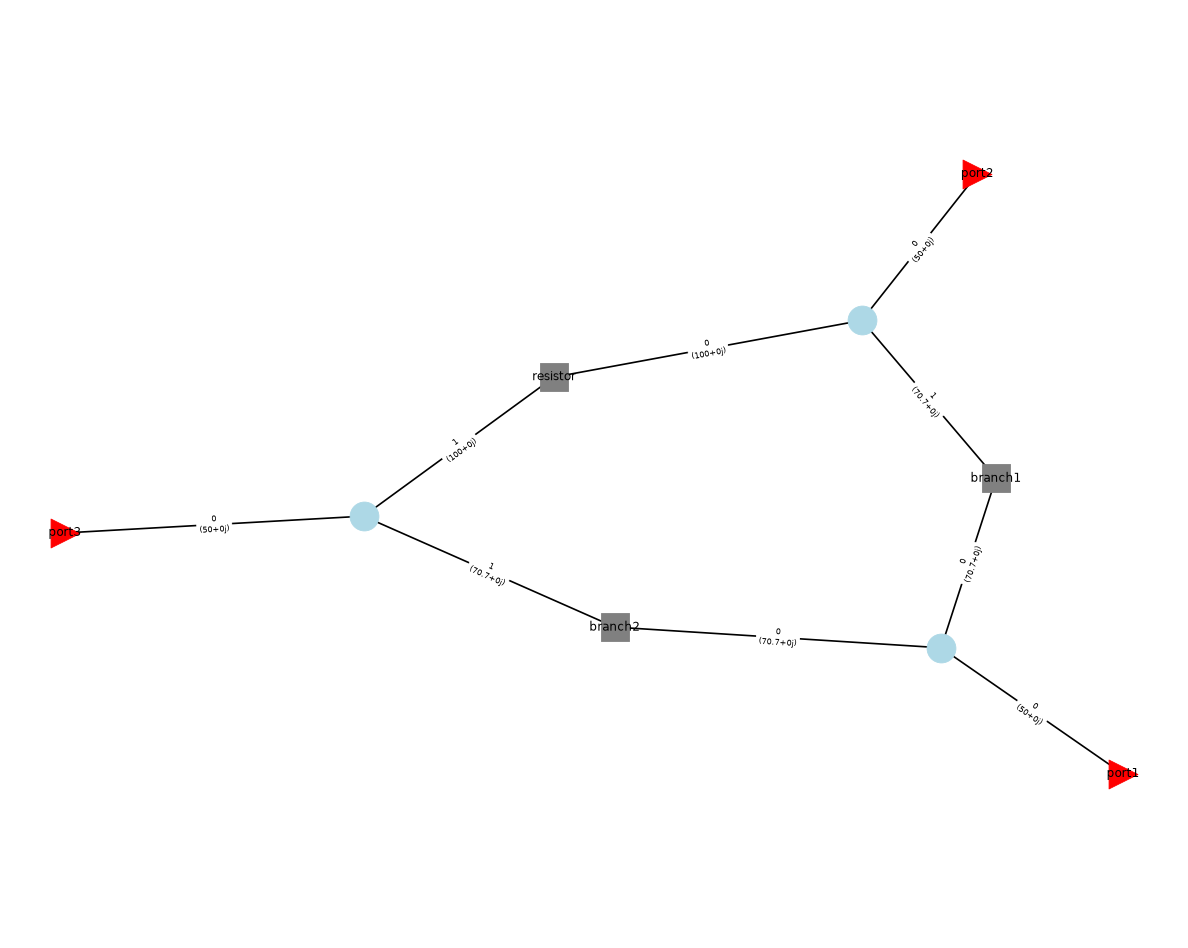

In [3]:
C.plot_graph(network_labels=True, edge_labels=True, port_labels=True, port_fontize=2)

Let's look to the scattering parameters of the circuit:

Text(0.5, 0.98, 'Ideal Wilkinson Divider @ 1 GHz')

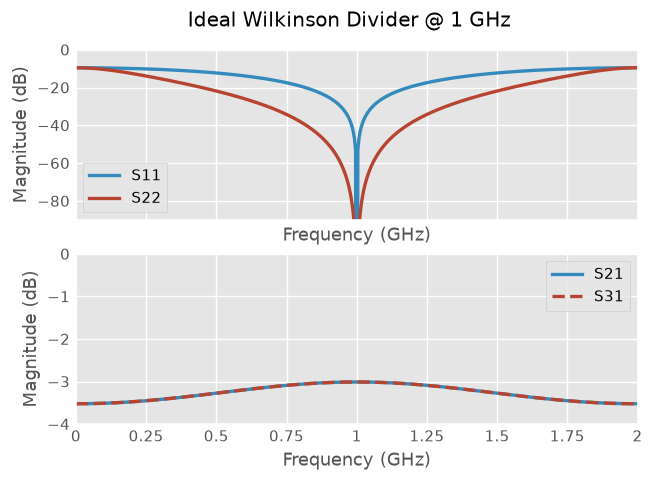

In [4]:
fig, (ax1,ax2) = plt.subplots(2, 1, sharex=True)
C.network.plot_s_db(ax=ax1, m=0, n=0,  lw=2)  # S11
C.network.plot_s_db(ax=ax1, m=1, n=1,  lw=2)  # S22
ax1.set_ylim(-90, 0)
C.network.plot_s_db(ax=ax2, m=1, n=0,  lw=2)  # S21
C.network.plot_s_db(ax=ax2, m=2, n=0,  ls='--', lw=2)  # S31
ax2.set_ylim(-4, 0)
fig.suptitle('Ideal Wilkinson Divider @ 1 GHz')

## Currents and Voltages
In the previous examples, we didn't have many internal ports because we connected the N ports directly to the external ports. However, in more complex scenarios, circuits can have many internal ports.

Additionally, the earlier examples featured circuits with components connected in series. As circuit complexity increases, it becomes inevitable that some components will be connected in parallel, which introduces new challenges for calculating current and voltage.

Fortunately, scikit-rf is well-equipped to handle these complex circuit scenarios. It is possible to calculate the currents and voltages at the circuit's internal ports.

In [5]:
power = [1,0,0]
phase = [0,0,0]
C.voltages(power, phase)  # or C2.currents(power, phase)

array([[ 6.66666667+0.00000000e+00j,  6.66666667+0.00000000e+00j,
         6.66666667+0.00000000e+00j, ...,  6.66666667+0.00000000e+00j,
         6.66666667+0.00000000e+00j,  6.66666667+0.00000000e+00j],
       [ 6.66678364+1.97457133e-02j,  6.66678364+1.97457133e-02j,
         6.66678364+1.97457133e-02j, ...,  6.66656431-3.94922062e-02j,
         6.66656431-3.94922062e-02j,  6.66656431-3.94922062e-02j],
       [ 6.66713454+3.94888282e-02j,  6.66713454+3.94888282e-02j,
         6.66713454+3.94888282e-02j, ...,  6.66625725-7.89838926e-02j,
         6.66625725-7.89838926e-02j,  6.66625725-7.89838926e-02j],
       ...,
       [ 6.66713454-3.94888282e-02j,  6.66713454-3.94888282e-02j,
         6.66713454-3.94888282e-02j, ..., -6.66625725-7.89838926e-02j,
        -6.66625725-7.89838926e-02j, -6.66625725-7.89838926e-02j],
       [ 6.66678364-1.97457133e-02j,  6.66678364-1.97457133e-02j,
         6.66678364-1.97457133e-02j, ..., -6.66656431-3.94922062e-02j,
        -6.66656431-3.94922062e-02j

Alternatively, you can use splitting Networks, such as "T" Networks in our case, to create circuits with only pairs of connections and perform current and voltage calculations. While using splitting Networks aligns more closely with 'classic' way for building a circuit, it has disadvantages in terms of code readability, complexity, and computational performance.

In [6]:
tee1 = line_branches.tee(name='tee1')
tee2 = line_branches.tee(name='tee2')
tee3 = line_branches.tee(name='tee3')

cnx = [
    [(port1, 0), (tee1, 0)],
    [(tee1, 1), (branch1, 0)],
    [(tee1, 2), (branch2, 0)],
    [(branch1, 1), (tee2, 0)],
    [(branch2, 1), (tee3, 0)],
    [(tee2, 2), (resistor, 0)],
    [(tee3, 2), (resistor, 1)],
    [(tee3, 1), (port3, 0)],
    [(tee2, 1), (port2, 0)],
]
C2 = Circuit(cnx)

The resulting graph is a bit more stuffed:

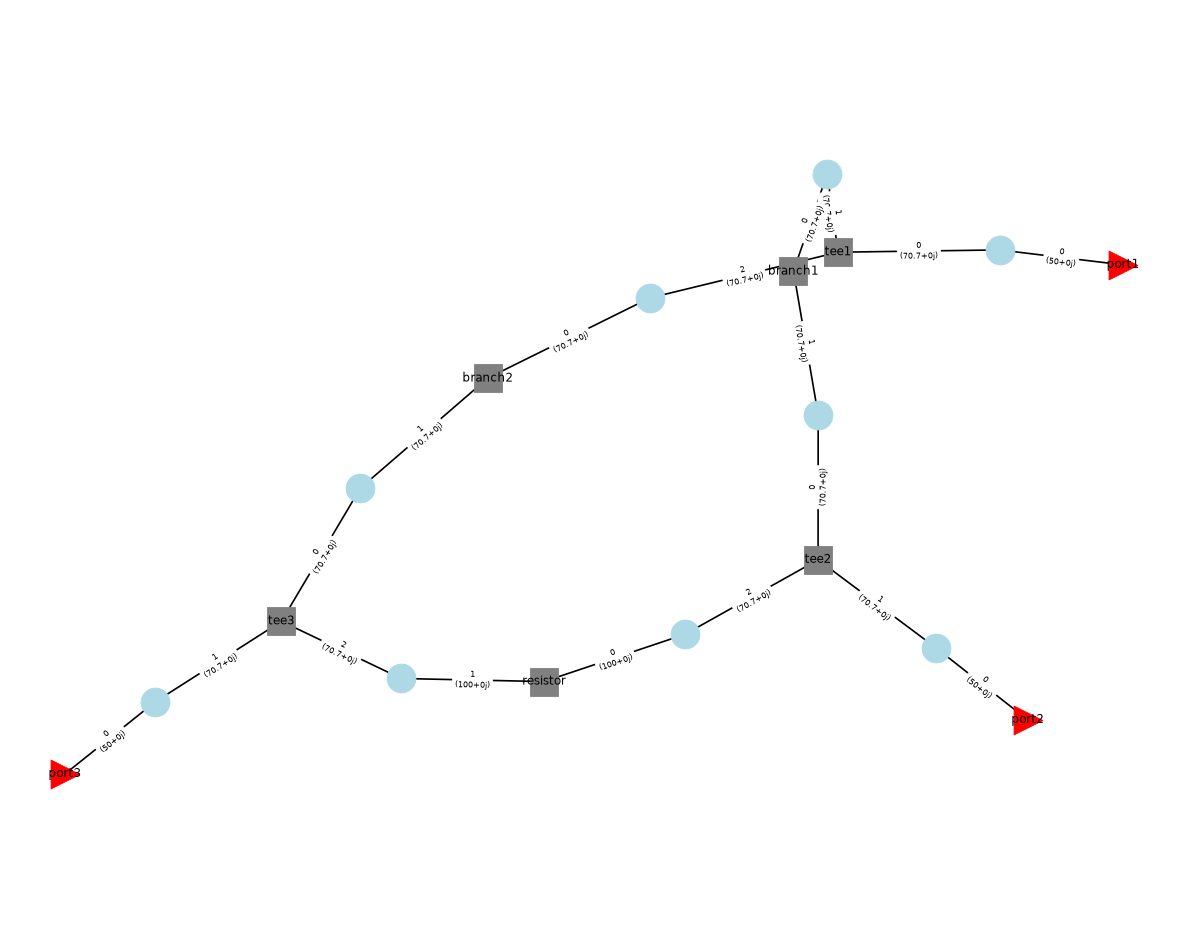

In [7]:
C2.plot_graph(network_labels=True, edge_labels=True, port_labels=True, port_fontize=2)

But the results are the same:

In [8]:
C.network == C2.network

True

Text(0.5, 0.98, 'Ideal Wilkinson Divider (2nd way) @ 1 GHz')

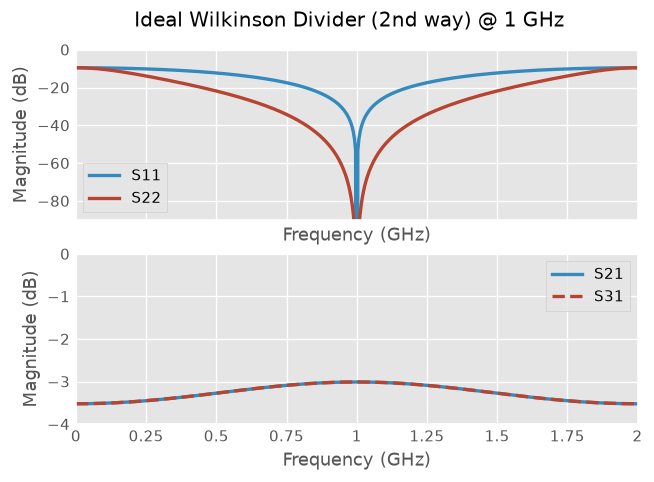

In [9]:
fig, (ax1,ax2) = plt.subplots(2, 1, sharex=True)
C2.network.plot_s_db(ax=ax1, m=0, n=0,  lw=2)  # S11
C2.network.plot_s_db(ax=ax1, m=1, n=1,  lw=2)  # S22
ax1.set_ylim(-90, 0)
C2.network.plot_s_db(ax=ax2, m=1, n=0,  lw=2)  # S21
C2.network.plot_s_db(ax=ax2, m=2, n=0,  ls='--', lw=2)  # S31
ax2.set_ylim(-4, 0)
fig.suptitle('Ideal Wilkinson Divider (2nd way) @ 1 GHz')

And the internal voltages and currents are also consistent.

In [10]:
C2.voltages(power, phase)  # or C2.currents(power, phase)

array([[ 6.66666667+0.00000000e+00j,  6.66666667+0.00000000e+00j,
         6.66666667+0.00000000e+00j, ...,  6.66666667+0.00000000e+00j,
         6.66666667+0.00000000e+00j,  6.66666667+0.00000000e+00j],
       [ 6.66678364+1.97457133e-02j,  6.66678364+1.97457133e-02j,
         6.66678364+1.97457133e-02j, ...,  6.66656431-3.94922062e-02j,
         6.66656431-3.94922062e-02j,  6.66656431-3.94922062e-02j],
       [ 6.66713454+3.94888282e-02j,  6.66713454+3.94888282e-02j,
         6.66713454+3.94888282e-02j, ...,  6.66625725-7.89838926e-02j,
         6.66625725-7.89838926e-02j,  6.66625725-7.89838926e-02j],
       ...,
       [ 6.66713454-3.94888282e-02j,  6.66713454-3.94888282e-02j,
         6.66713454-3.94888282e-02j, ..., -6.66625725-7.89838926e-02j,
        -6.66625725-7.89838926e-02j, -6.66625725-7.89838926e-02j],
       [ 6.66678364-1.97457133e-02j,  6.66678364-1.97457133e-02j,
         6.66678364-1.97457133e-02j, ..., -6.66656431-3.94922062e-02j,
        -6.66656431-3.94922062e-02j

You will find more details on voltages and currents calculation on the dedicated example.